# Analisis & Prediksi Kualitas Udara Jakarta

Proyek portofolio data science — analisis pola PM2.5 Jakarta dan prediksi AQI menggunakan data real dari [OpenAQ](https://openaq.org).

## Setup
Pastikan sudah menjalankan `fetch_data.py` terlebih dahulu untuk mendapatkan `data/locations.csv` dan `data/pm25_jakarta_daily.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

locations = pd.read_csv('data/locations.csv')
df = pd.read_csv('data/pm25_jakarta_daily.csv')
df['date'] = pd.to_datetime(df['date'], utc=True).dt.tz_convert('Asia/Jakarta')

print(f"{len(df)} baris, {df['location_name'].nunique()} stasiun")
print(f"Rentang: {df['date'].min()} s/d {df['date'].max()}")
df.head()

4664 baris, 10 stasiun
Rentang: 2023-01-01 00:00:00+07:00 s/d 2026-08-19 00:00:00+07:00


,location_id,location_name,latitude,longitude,date,value,parameter
0,8320,Jakarta South,-6.236704,106.793244,2023-05-07 00:00:00+07:00,NaN,pm25
1,8320,Jakarta South,-6.236704,106.793244,2023-05-08 00:00:00+07:00,NaN,pm25
2,8320,Jakarta South,-6.236704,106.793244,2023-05-09 00:00:00+07:00,45.9,pm25
3,8320,Jakarta South,-6.236704,106.793244,2023-05-10 00:00:00+07:00,52.5,pm25
4,8320,Jakarta South,-6.236704,106.793244,2023-05-11 00:00:00+07:00,28.8,pm25


## 1. Deteksi Anomali

Cek statistik ringkas untuk melihat apakah ada nilai yang mencurigakan.

In [2]:
df['value'].describe()

count    4058.000000
mean       42.323701
std        24.505311
min         0.000000
25%        27.000000
50%        41.700000
75%        54.600000
max       545.000000
Name: value, dtype: float64

Nilai `max` jauh di atas kuartil-3 — perlu digali lebih lanjut. Lihat baris-baris dengan nilai tertinggi:

In [3]:
df.nlargest(5, 'value')[['location_name', 'date', 'value']]

,location_name,date,value
1055,Jakarta Central,2023-07-24 00:00:00+07:00,545.0
1435,Jakarta Central,2024-08-07 00:00:00+07:00,522.0
1433,Jakarta Central,2024-08-05 00:00:00+07:00,515.0
1013,Jakarta Central,2023-06-12 00:00:00+07:00,246.0
1043,Jakarta Central,2023-07-12 00:00:00+07:00,190.0


4 dari 5 nilai teratas berasal dari stasiun yang sama (`Jakarta Central`). Cross-check ke stasiun lain di tanggal yang sama untuk memastikan ini kejadian polusi nyata atau kemungkinan sensor error:

In [4]:
tanggal_curiga = '2024-08-07'
df[df['date'].dt.strftime('%Y-%m-%d') == tanggal_curiga][['location_name', 'value']]

,location_name,value
441,Jakarta South,41.2
1435,Jakarta Central,522.0
2009,Qoryah Darussalam,75.1
2695,Jakarta,51.8
3261,Krukut,51.9
3379,West Jakarta Mayor Office,49.5
4349,Rusunawa Marunda,55.6


Stasiun lain di tanggal yang sama menunjukkan nilai normal (41–75 µg/m³), sementara Jakarta Central melonjak ke 500+. Karena polusi udara adalah fenomena regional (bukan titik tunggal), ini kemungkinan besar bukan kejadian atmosfer nyata melainkan glitch sensor. Exclude titik data ini secara spesifik (bukan seluruh stasiunnya):

In [5]:
anomaly_mask = (
    (df['location_name'] == 'Jakarta Central') &
    (df['value'].isin([545.0, 522.0, 515.0, 246.0]))
)

anomalies = df[anomaly_mask].copy()
anomalies['reason'] = 'Tidak dikonfirmasi stasiun tetangga; diduga sensor glitch'
anomalies.to_csv('data/anomalies_removed.csv', index=False)

df_clean = df[~anomaly_mask].copy()
df_clean.to_csv('data/pm25_jakarta_daily_cleaned.csv', index=False)

print(f"{len(anomalies)} baris dibuang, {len(df_clean)} baris tersisa")
print(f"Mean sebelum: {df['value'].mean():.2f} | sesudah: {df_clean['value'].mean():.2f}")

4 baris dibuang, 4660 baris tersisa
Mean sebelum: 42.32 | sesudah: 41.91


## 2. Missing Values

Cek dulu berapa nilai yang kosong (NaN) di data yang ada sekarang:

In [6]:
df_clean['value'].isna().sum()

np.int64(606)

**Awas — angka ini menipu.** Baris cuma ada untuk hari-hari yang memang dikembalikan API. Untuk stasiun sensor low-cost yang jarang lapor, hari yang bolong itu **gak muncul sebagai baris NaN, tapi hilang sama sekali** dari data. Jadi sebelum hitung missing value yang bener, kita perlu bikin dulu "grid" tanggal harian yang lengkap untuk tiap stasiun (dari tanggal pertama sampai terakhir stasiun itu aktif) — baru celah aslinya kelihatan semua.

In [7]:
daily_frames = []
for station in df_clean['location_name'].unique():
    sub = df_clean[df_clean['location_name'] == station].set_index('date').sort_index()
    full_range = pd.date_range(sub.index.min(), sub.index.max(), freq='D')
    sub = sub.reindex(full_range)
    sub['location_name'] = station
    sub['location_id'] = sub['location_id'].ffill().bfill()
    sub['latitude'] = sub['latitude'].ffill().bfill()
    sub['longitude'] = sub['longitude'].ffill().bfill()
    sub.index.name = 'date'
    daily_frames.append(sub.reset_index())

df_grid = pd.concat(daily_frames, ignore_index=True)

print(f"Baris sebelum reindex: {len(df_clean)}")
print(f"Baris sesudah (grid harian penuh per stasiun): {len(df_grid)}")
print(f"Missing value yang sebenarnya: {df_grid['value'].isna().sum()} ({df_grid['value'].isna().mean()*100:.1f}%)")

Baris sebelum reindex: 4660
Baris sesudah (grid harian penuh per stasiun): 5625
Missing value yang sebenarnya: 1571 (27.9%)


Ternyata missing value aslinya jauh lebih banyak dari yang kelihatan sebelumnya — sebagian besar celah itu sebelumnya "tersembunyi" karena barisnya memang gak pernah ada.

Sekarang cek pola gap-nya (apakah tersebar random atau ngumpul jadi blok panjang):

In [8]:
def cari_gap(df, station):
    sub = df[df['location_name'] == station].sort_values('date').reset_index(drop=True)
    sub['is_missing'] = sub['value'].isna()
    sub['gap_group'] = (sub['is_missing'] != sub['is_missing'].shift()).cumsum()
    gaps = (
        sub[sub['is_missing']]
        .groupby('gap_group')
        .agg(start=('date', 'min'), end=('date', 'max'), length=('date', 'count'))
        .sort_values('length', ascending=False)
    )
    return gaps

for station in ['Jakarta Central', 'Jakarta South']:
    print(f"=== {station} ===")
    print(cari_gap(df_grid, station).head(3))
    print()

=== Jakarta Central ===
                              start                       end  length
gap_group                                                            
223       2025-01-09 00:00:00+07:00 2025-03-03 00:00:00+07:00      54
13        2023-02-16 00:00:00+07:00 2023-03-21 00:00:00+07:00      34
83        2023-12-23 00:00:00+07:00 2024-01-16 00:00:00+07:00      25

=== Jakarta South ===
                              start                       end  length
gap_group                                                            
3         2023-05-23 00:00:00+07:00 2023-08-30 00:00:00+07:00     100
37        2025-01-31 00:00:00+07:00 2025-02-18 00:00:00+07:00      19
29        2024-07-21 00:00:00+07:00 2024-08-05 00:00:00+07:00      16



Gap-nya ngumpul jadi blok panjang (sampai puluhan hari) — kemungkinan alat lagi maintenance/offline, bukan noise sesaat. Interpolasi cuma masuk akal untuk gap **pendek** (≤3 hari); gap panjang dibiarkan kosong, jangan dipaksa isi (nanti jadi karang-karang data palsu berbulan-bulan).

Satu jebakan: parameter bawaan pandas `interpolate(limit=3, limit_direction='both')` **bukan** berarti "isi gap ≤3 hari" secara persis — kombinasi forward+backward itu bisa nembus sampai gap 6 hari (3 dari kiri + 3 dari kanan, saling tumpang tindih). Supaya sesuai maksud aslinya, hitung dulu panjang tiap gap secara eksplisit, baru filter mana yang boleh diisi:

In [9]:
def interpolate_short_gaps_explicit(s, max_gap=3):
    s = s.copy()
    is_na = s.isna()
    gap_id = (is_na != is_na.shift()).cumsum()
    gap_lengths = is_na.groupby(gap_id).transform('sum')
    fillable = is_na & (gap_lengths <= max_gap)
    interpolated = s.interpolate(method='linear', limit_direction='both')
    s[fillable] = interpolated[fillable]
    return s

df_grid['value'] = df_grid.groupby('location_name')['value'].transform(interpolate_short_gaps_explicit)
df_grid.to_csv('data/pm25_jakarta_daily_filled.csv', index=False)

print(f"Missing value sesudah interpolasi gap pendek: {df_grid['value'].isna().sum()}")

Missing value sesudah interpolasi gap pendek: 1296


## 3. Pola Musiman & Perbandingan Stasiun

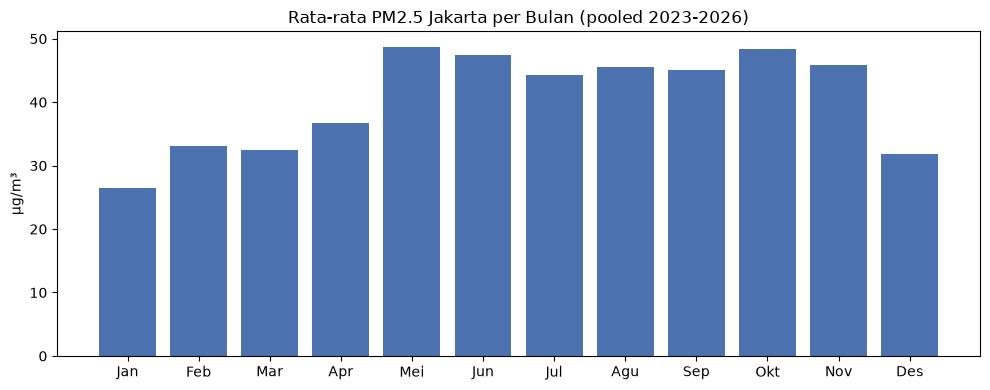

In [10]:
monthly = df_grid.groupby(df_grid['date'].dt.month)['value'].mean()
month_labels = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']

plt.figure(figsize=(10, 4))
plt.bar(month_labels, monthly.values, color='#4C72B0')
plt.title('Rata-rata PM2.5 Jakarta per Bulan (pooled 2023-2026)')
plt.ylabel('µg/m³')
plt.tight_layout()
plt.show()

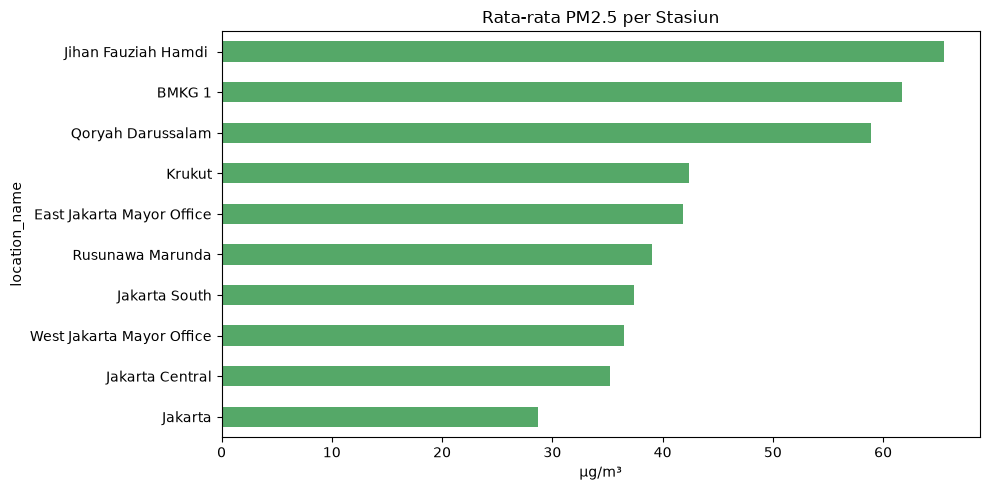

In [11]:
station_avg = df_grid.groupby('location_name')['value'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
station_avg.plot(kind='barh', color='#55A868')
plt.title('Rata-rata PM2.5 per Stasiun')
plt.xlabel('µg/m³')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Feature Engineering

Polusi udara punya inersia — nilai hari ini biasanya mirip beberapa hari sebelumnya (partikel gak langsung hilang). Karena data sekarang sudah dalam grid harian yang rapat (bukan baris yang lompat-lompat), `shift(n)` di bawah ini benar-benar berarti "n hari kalender yang lalu", bukan sekadar "n baris sebelumnya".

In [12]:
df_grid = df_grid.sort_values(['location_name', 'date']).reset_index(drop=True)

df_grid['lag_1'] = df_grid.groupby('location_name')['value'].transform(lambda s: s.shift(1))
df_grid['lag_2'] = df_grid.groupby('location_name')['value'].transform(lambda s: s.shift(2))
df_grid['lag_3'] = df_grid.groupby('location_name')['value'].transform(lambda s: s.shift(3))
df_grid['lag_7'] = df_grid.groupby('location_name')['value'].transform(lambda s: s.shift(7))

# rolling mean dihitung dari data SEBELUM hari ini (shift(1) dulu baru rolling)
# supaya nilai hari ini sendiri gak ikut "bocor" ke fiturnya
df_grid['rolling_mean_3'] = df_grid.groupby('location_name')['value'].transform(lambda s: s.shift(1).rolling(3).mean())
df_grid['rolling_mean_7'] = df_grid.groupby('location_name')['value'].transform(lambda s: s.shift(1).rolling(7).mean())

df_grid['month'] = df_grid['date'].dt.month
df_grid['day_of_week'] = df_grid['date'].dt.dayofweek
df_grid['is_weekend'] = df_grid['day_of_week'].isin([5, 6]).astype(int)
df_grid['is_musim_kemarau'] = df_grid['month'].isin([5, 6, 7, 8, 9, 10]).astype(int)

df_grid.head()

,date,location_id,location_name,latitude,longitude,value,parameter,lag_1,lag_2,lag_3,lag_7,rolling_mean_3,rolling_mean_7,month,day_of_week,is_weekend,is_musim_kemarau
0,2026-07-22 00:00:00+07:00,6455006.0,BMKG 1,-6.155769,106.842394,47.1,pm25,NaN,NaN,NaN,NaN,NaN,NaN,7,2,0,1
1,2026-07-23 00:00:00+07:00,6455006.0,BMKG 1,-6.155769,106.842394,42.8,pm25,47.1,NaN,NaN,NaN,NaN,NaN,7,3,0,1
2,2026-07-24 00:00:00+07:00,6455006.0,BMKG 1,-6.155769,106.842394,36.2,pm25,42.8,47.1,NaN,NaN,NaN,NaN,7,4,0,1
3,2026-07-25 00:00:00+07:00,6455006.0,BMKG 1,-6.155769,106.842394,42.2,pm25,36.2,42.8,47.1,NaN,42.033333,NaN,7,5,1,1
4,2026-07-26 00:00:00+07:00,6455006.0,BMKG 1,-6.155769,106.842394,55.1,pm25,42.2,36.2,42.8,NaN,40.400000,NaN,7,6,1,1


Baris di awal tiap stasiun (dan di sekitar gap panjang) bakal punya fitur lag/rolling yang NaN — wajar, karena memang gak ada histori sebelumnya untuk dihitung. Baris-baris ini gak bisa dipakai untuk training.

In [13]:
feature_cols = ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'rolling_mean_3', 'rolling_mean_7']
df_ready = df_grid.dropna(subset=feature_cols + ['value'])

print(f"Total baris (grid harian): {len(df_grid)}")
print(f"Baris siap dipakai training: {len(df_ready)}")

df_ready.to_csv('data/pm25_jakarta_features.csv', index=False)
df_ready[['location_name', 'date', 'value'] + feature_cols].head()

Total baris (grid harian): 5625
Baris siap dipakai training: 3801


,location_name,date,value,lag_1,lag_2,lag_3,lag_7,rolling_mean_3,rolling_mean_7
7,BMKG 1,2026-07-29 00:00:00+07:00,53.8,51.1,62.1,55.1,47.1,56.100000,48.085714
8,BMKG 1,2026-07-30 00:00:00+07:00,67.5,53.8,51.1,62.1,42.8,55.666667,49.042857
27,BMKG 1,2026-08-18 00:00:00+07:00,53.5,68.6,76.5,84.6,78.7,76.566667,75.314286
28,BMKG 1,2026-08-19 00:00:00+07:00,58.3,53.5,68.6,76.5,70.2,66.200000,71.714286
36,East Jakarta Mayor Office,2023-10-07 00:00:00+07:00,67.8,59.5,45.4,51.2,70.3,52.033333,55.514286


## 5. Model Prediksi

kalau di-split random (train_test_split biasa), data "masa depan" bisa nyasar ke training set, model jadi curang (udah pernah "lihat" pola yang harusnya belum terjadi). Makanya kita potong berdasarkan tanggal: data lama buat belajar, data terbaru buat diuji.

In [14]:
dates_sorted = df_ready['date'].sort_values().unique()
cutoff_date = dates_sorted[int(len(dates_sorted) * 0.8)]

train = df_ready[df_ready['date'] < cutoff_date]
test = df_ready[df_ready['date'] >= cutoff_date]

print(f"Cutoff: {cutoff_date}")
print(f"Train: {len(train)} baris | Test: {len(test)} baris")

Cutoff: 2025-07-10 00:00:00+07:00
Train: 3420 baris | Test: 381 baris


Baseline — model paling bodoh yang jujur

Sebelum pakai model canggih, wajib punya pembanding sederhana dulu: "prediksi besok = nilai hari ini" (persistence model). Kalau model canggih gak bisa ngalahin ini, berarti dia gak benar-benar belajar apa-apa.

In [15]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

baseline_pred = test['lag_1']
mae_baseline = mean_absolute_error(test['value'], baseline_pred)
rmse_baseline = root_mean_squared_error(test['value'], baseline_pred)
print(f"Baseline (persistence) -> MAE: {mae_baseline:.2f}, RMSE: {rmse_baseline:.2f}")

Baseline (persistence) -> MAE: 6.82, RMSE: 9.86


In [16]:
#Random Forest
from sklearn.ensemble import RandomForestRegressor

feature_cols = ['lag_1','lag_2','lag_3','lag_7','rolling_mean_3','rolling_mean_7',
                 'month','day_of_week','is_weekend','is_musim_kemarau']

train_X = pd.get_dummies(train[feature_cols + ['location_name']], columns=['location_name'])
test_X = pd.get_dummies(test[feature_cols + ['location_name']], columns=['location_name'])
test_X = test_X.reindex(columns=train_X.columns, fill_value=0)

model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
model.fit(train_X, train['value'])
pred = model.predict(test_X)

mae_model = mean_absolute_error(test['value'], pred)
rmse_model = root_mean_squared_error(test['value'], pred)
print(f"Random Forest -> MAE: {mae_model:.2f}, RMSE: {rmse_model:.2f}")

Random Forest -> MAE: 7.70, RMSE: 10.23


Random Forest KALAH dari baseline — MAE 7.79 vs 6.82. Model "canggih" malah lebih buruk dari sekadar nebak "besok = hari ini

In [17]:
# target baru: selisih dari kemarin, bukan nilai absolut
train['delta'] = train['value'] - train['lag_1']
test['delta'] = test['value'] - test['lag_1']

model_delta = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
model_delta.fit(train_X, train['delta'])
pred_delta = model_delta.predict(test_X)

# rekonstruksi prediksi asli: nilai kemarin + selisih yang diprediksi
pred_value = test['lag_1'] + pred_delta

mae_delta_model = mean_absolute_error(test['value'], pred_value)
rmse_delta_model = root_mean_squared_error(test['value'], pred_value)

print(f"Baseline (persistence) -> MAE: {mae_baseline:.2f}, RMSE: {rmse_baseline:.2f}")
print(f"RF prediksi delta      -> MAE: {mae_delta_model:.2f}, RMSE: {rmse_delta_model:.2f}")

Baseline (persistence) -> MAE: 6.82, RMSE: 9.86
RF prediksi delta      -> MAE: 7.17, RMSE: 9.52


gap yang tersisa sekarang kemungkinan besar karena kita ngegabung 10 stasiun jadi satu model, padahal karakteristiknya beda jauh — dari EDA awal kita udah liat sendiri, rata-rata PM2.5 antar stasiun bisa beda sampai 2x lipat (31 vs 65 µg/m³), belum lagi bedanya sensor low-cost vs reference-grade. One-hot encoding buat location_name itu belum tentu cukup buat tree model nangkep dinamika unik tiap stasiun.

In [18]:
import requests
import pandas as pd

JAKARTA_LAT = -6.2088
JAKARTA_LON = 106.8456

def fetch_weather(start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": JAKARTA_LAT,
        "longitude": JAKARTA_LON,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max,winddirection_10m_dominant",
        "timezone": "Asia/Jakarta",
    }
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()
    data = resp.json()["daily"]
    return pd.DataFrame(data)

weather = fetch_weather("2023-01-01", "2026-08-19")
weather.to_csv("data/jakarta_weather.csv", index=False)
print(weather.shape)
print(weather.head())

(1327, 6)
         time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0  2023-01-01                28.7                21.8               17.2   
1  2023-01-02                29.5                22.8               11.9   
2  2023-01-03                26.8                23.3               19.4   
3  2023-01-04                29.5                22.3               10.3   
4  2023-01-05                30.7                22.8                0.9   

   windspeed_10m_max  winddirection_10m_dominant  
0               12.2                         253  
1               16.9                         268  
2               16.2                         262  
3               14.2                         272  
4               16.1                         271  


In [20]:
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

feature_cols = ['lag_1','lag_2','lag_3','lag_7','rolling_mean_3','rolling_mean_7',
                 'month','day_of_week','is_weekend','is_musim_kemarau']

dates_sorted = df_ready['date'].sort_values().unique()
cutoff = dates_sorted[int(len(dates_sorted) * 0.8)]
train = df_ready[df_ready['date'] < cutoff].copy()
test = df_ready[df_ready['date'] >= cutoff].copy()
train['delta'] = train['value'] - train['lag_1']

In [21]:
train_X = pd.get_dummies(train[feature_cols + ['location_name']], columns=['location_name']).astype(float)
test_X = pd.get_dummies(test[feature_cols + ['location_name']], columns=['location_name']).astype(float)
test_X = test_X.reindex(columns=train_X.columns, fill_value=0)

means, stds = train_X.mean(), train_X.std().replace(0, 1)
train_Xs, test_Xs = (train_X - means) / stds, (test_X - means) / stds

In [22]:
mae_baseline = mean_absolute_error(test['value'], test['lag_1'])
rmse_baseline = root_mean_squared_error(test['value'], test['lag_1'])

In [23]:
models = {
    'Linear Regression': (LinearRegression(), True),
    'Ridge (alpha=10)': (Ridge(alpha=10.0), True),
    'KNN (k=15)': (KNeighborsRegressor(n_neighbors=15), True),
    'Random Forest': (RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42), False),
    'Extra Trees': (ExtraTreesRegressor(n_estimators=200, max_depth=10, random_state=42), False),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=200, max_depth=3, random_state=42), False),
    'HistGradientBoosting': (HistGradientBoostingRegressor(max_depth=5, random_state=42), False),
}

In [24]:
print(f"{'Model':<25} {'MAE':>8} {'RMSE':>8} {'vs baseline':>12}")
print(f"{'Baseline (persistence)':<25} {mae_baseline:>8.2f} {rmse_baseline:>8.2f} {'-':>12}")

for name, (model, use_scaled) in models.items():
    X_tr, X_te = (train_Xs, test_Xs) if use_scaled else (train_X, test_X)
    model.fit(X_tr, train['delta'])
    pred_value = test['lag_1'] + model.predict(X_te)
    mae = mean_absolute_error(test['value'], pred_value)
    rmse = root_mean_squared_error(test['value'], pred_value)
    pct = (1 - mae / mae_baseline) * 100
    print(f"{name:<25} {mae:>8.2f} {rmse:>8.2f} {pct:>11.1f}%")

Model                          MAE     RMSE  vs baseline
Baseline (persistence)        6.82     9.86            -
Linear Regression             9.45    11.43       -38.6%
Ridge (alpha=10)              9.44    11.42       -38.5%
KNN (k=15)                    7.66    10.08       -12.4%
Random Forest                 7.17     9.52        -5.2%
Extra Trees                   7.33     9.46        -7.5%
Gradient Boosting             8.41    10.81       -23.4%
HistGradientBoosting          7.86    10.27       -15.4%


- Kolom MAE & RMSE — makin kecil makin bagus (itu ukuran seberapa jauh meleset, dijelasin lengkap sebelumnya). Kolom "vs baseline" — persen negatif berarti model itu LEBIH BURUK dari sekadar nebak "besok = hari ini"; gak ada satupun yang positif di sini.
- Linear Regression & Ridge paling buncit (-38%) — ini bukan soal cuaca (emang gak dipake di sini), tapi soal lag_1, lag_2, lag_3, lag_7, rolling_mean_3, rolling_mean_7 itu SALING MIRIP SATU SAMA LAIN (semua diturunin dari deret yang sama). Model linear gampang "bingung" bagi bobot antar fitur yang mirip gitu — hasilnya prediksi jadi liar dan gak stabil pas ketemu data baru (test set).
- KNN di tengah-tengah (-12.4%) — KNN nyari "titik data paling mirip di masa lalu" buat nebak. Lumayan, tapi gak sekuat pohon keputusan buat pola kayak gini.
- Random Forest & Extra Trees paling deket sama baseline — dan Extra Trees malah menang di RMSE (9.46 < 9.86). Artinya dia paling jarang meleset ekstrem, walau rata-rata errornya (MAE) masih dikit di atas baseline.
- Gradient Boosting & HistGradientBoosting justru lebih buruk dari Random Forest — ini di luar dugaan umum (biasanya boosting lebih jago), tapi wajar karena parameternya masih tebakan kasar, belum di-tuning sama sekali.

## Kesimpulan

**Tujuan:** menganalisis pola kualitas udara (PM2.5) Jakarta dan menguji
seberapa jauh data historis bisa dipakai memprediksi nilai hari berikutnya,
menggunakan data real dari 10 stasiun pemantauan (OpenAQ, Jan 2023–Agu 2026).

**Temuan kualitas data:**
- Ditemukan 4 nilai anomali di satu stasiun (Jakarta Central) yang tidak
  terkonfirmasi oleh stasiun tetangga di tanggal yang sama — dikeluarkan
  dari analisis, bukan seluruh stasiunnya.
- Missing value tersembunyi (baris yang tidak pernah ada, bukan cuma NaN)
  ditemukan setelah data di-reindex ke grid harian penuh per stasiun —
  gap pendek (≤3 hari) diinterpolasi, gap panjang dibiarkan kosong.

**Temuan pola:**
- Rata-rata PM2.5 Jakarta (42.3 µg/m³) sekitar 2.8x ambang batas 24 jam WHO.
- Pola musiman jelas: musim kemarau (Mei–Okt) signifikan lebih buruk
  daripada musim hujan — konsisten dengan penjelasan fisis (tidak ada hujan
  yang "mencuci" polutan).

**Hasil pemodelan (jujur, bukan yang terbaik):**
- Baseline naif ("besok = hari ini") ternyata sangat kompetitif — MAE 6.82,
  RMSE 9.86 — karena PM2.5 harian punya autokorelasi tinggi.
- Reframing target ke selisih (delta) + model berbasis pohon (Extra Trees)
  memberi perbaikan tipis di RMSE (9.46), MAE mendekati baseline.
- Model linear gagal total (multikolinearitas antar fitur lag).
- Menambah data cuaca (Open-Meteo) justru memperburuk hasil — korelasi
  fisis yang diharapkan (curah hujan, angin) ternyata lemah (r=0.18–0.28)
  dibanding sinyal autokorelasi yang sudah dominan.

**Keterbatasan & pengembangan lanjutan:**
- Fitur cuaca yang dipakai adalah cuaca aktual historis, bukan data
  ramalan — untuk sistem prediksi nyata dibutuhkan data forecast asli.
- Horizon prediksi hanya 1 hari, di mana baseline persistence secara
  alami sudah kuat; horizon lebih panjang (3–7 hari) kemungkinan
  memberi ruang lebih besar bagi model untuk unggul.
- Variabel fisis tambahan (ketinggian boundary layer atmosfer, data
  lalu lintas) belum dieksplorasi.

In [25]:
import joblib

# latih ulang Extra Trees pakai SEMUA data (bukan cuma train set) — 
# karena buat dashboard produksi, kita mau model paling "tau banyak"
final_model = ExtraTreesRegressor(n_estimators=200, max_depth=10, random_state=42)
final_model.fit(pd.concat([train_X, test_X]), pd.concat([train['delta'], 
    (test['value'] - test['lag_1'])]))

joblib.dump(final_model, 'model_pm25.joblib')
joblib.dump(list(train_X.columns), 'model_columns.joblib')
print("Model tersimpan.")

Model tersimpan.


## Next steps
- [x] Deteksi & bersihkan anomali sensor
- [x] Missing values (reindex ke grid harian, interpolasi gap pendek, gap panjang dibiarkan)
- [x] Feature engineering (lag features, rolling mean, indikator musim/hari)
- [ ] Model prediksi (mulai dari baseline sederhana, baru naik ke model yang lebih kuat)
- [ ] Dashboard interaktif (Streamlit)